## Tidy Data Project: 2008 Olympic Medalists 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("2008_medalists_all.csv")
df.head()

,medalist_wikidata_id,medalist_link,medalist_name,medal,delegation_wikidata_id,delegation_link,delegation_name,country_medal_wikidata_id,country_medal,country_medal_code2,...,nuts2_id,nuts2_name,nuts3_id,nuts3_name,nuts2_population,nuts3_population,nuts2_gdp,nuts3_gdp,nuts0_id,nuts0_name
0,Q362101,https://en.wikipedia.org/wiki/Viktor_Ruban,Viktor Ruban,gold,Q140335,https://en.wikipedia.org/wiki/Ukraine_at_the_2...,Ukraine at the 2008 Summer Olympics,Q212,Ukraine,UA,...,UA13,Kharkivska Oblast,UA136,Kharkivskyi Raion,NaN,NaN,NaN,NaN,UA,Ukraine
1,Q495207,https://en.wikipedia.org/wiki/Park_Kyung-Mo,Park Kyung-mo,silver,Q140477,https://en.wikipedia.org/wiki/South_Korea_at_t...,South Korea at the 2008 Summer Olympics,Q884,South Korea,KR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Q735897,https://en.wikipedia.org/wiki/Bair_Bad%C3%ABnov,Bair Badënov,bronze,Q139788,https://en.wikipedia.org/wiki/Russia_at_the_20...,Russia at the 2008 Summer Olympics,Q159,Russia,RU,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Q197231,https://en.wikipedia.org/wiki/Zhang_Juanjuan,Zhang Juanjuan,gold,Q146621,https://en.wikipedia.org/wiki/China_at_the_200...,China at the 2008 Summer Olympics,Q148,People's Republic of China,CN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Q233884,https://en.wikipedia.org/wiki/Park_Sung-hyun_(...,Park Sung-hyun,silver,Q140477,https://en.wikipedia.org/wiki/South_Korea_at_t...,South Korea at the 2008 Summer Olympics,Q884,South Korea,KR,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


I started by importing pandas and Matplotlib and loading my CSV file using pd.read_csv(). I used df.head() to look at the first five rows of the dataset. I also used df.shape and df.info() to understand the number of rows and columns and examine the data types.

The original dataset had 46 columns, so I decided to focus on the variables that would be most useful for my analysis.

In [8]:
print(df.shape)
df.info()

(2050, 5)
<class 'pandas.DataFrame'>
RangeIndex: 2050 entries, 0 to 2049
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   medalist_name  2050 non-null   str  
 1   country_medal  2050 non-null   str  
 2   sport          2050 non-null   str  
 3   event_name     2050 non-null   str  
 4   medal          2050 non-null   str  
dtypes: str(5)
memory usage: 228.9 KB


In [4]:
df.describe()

,lat,lon,nuts2_population,nuts3_population,nuts2_gdp,nuts3_gdp
count,2035.000000,2035.000000,6.370000e+02,6.240000e+02,556.000000,528.000000
mean,30.495649,15.558697,2.871375e+06,1.138620e+06,120487.542482,48230.857292
std,27.731139,80.561691,2.277259e+06,1.450092e+06,120015.692303,57658.282579
min,-44.393056,-171.833333,3.534440e+05,4.246900e+04,6179.790000,636.740000
25%,26.820139,-52.304444,1.365884e+06,3.534440e+05,36011.140000,9877.557500
50%,40.262862,10.400000,2.126846e+06,6.053880e+05,81884.065000,22899.235000
75%,49.114444,73.975000,3.755251e+06,1.387643e+06,180224.270000,61923.290000
max,69.649610,176.833333,1.238839e+07,6.871903e+06,782639.160000,237540.310000


In [5]:
df = df[["medalist_name", "country_medal", "sport", "event_name", "medal"]]
df.head()

,medalist_name,country_medal,sport,event_name,medal
0,Viktor Ruban,Ukraine,archery,archery at the 2008 Summer Olympics – men's in...,gold
1,Park Kyung-mo,South Korea,archery,archery at the 2008 Summer Olympics – men's in...,silver
2,Bair Badënov,Russia,archery,archery at the 2008 Summer Olympics – men's in...,bronze
3,Zhang Juanjuan,People's Republic of China,archery,archery at the 2008 Summer Olympics – women's ...,gold
4,Park Sung-hyun,South Korea,archery,archery at the 2008 Summer Olympics – women's ...,silver


In [6]:
df.isnull().sum()

medalist_name    0
country_medal    0
sport            0
event_name       0
medal            0
dtype: int64

I selected five columns from the original dataset: medalist_name, country_medal, sport, event_name, and medal. I chose these variables because they gave me information about the athletes, their countries, the events they participated in, and the medals they received which I thought was the most important information I needed to create my analysis. 

I then used df.isnull().sum() to check for missing values. The results showed that there were no missing values in any of my five selected columns. This meant I did not need to remove or fill in any missing data.

In [10]:
df_medalists = df[["medalist_name", "country_medal", "sport", "event_name", "medal"]].copy()
df_medalists["event_name"] = df_medalists["event_name"].str.replace(
    " at the 2008 Summer Olympics", "", regex=False
)
df_medalists = df_medalists.drop_duplicates()
df_medalists.head()




,medalist_name,country_medal,sport,event_name,medal
0,Viktor Ruban,Ukraine,archery,archery – men's individual,gold
1,Park Kyung-mo,South Korea,archery,archery – men's individual,silver
2,Bair Badënov,Russia,archery,archery – men's individual,bronze
3,Zhang Juanjuan,People's Republic of China,archery,archery – women's individual,gold
4,Park Sung-hyun,South Korea,archery,archery – women's individual,silver


Next, I created a cleaned dataset called df_medalists. I used str.replace() to remove unnecessary information from the event names, which made them shorter and easier to understand. I also used drop_duplicates() to remove any repeated records. I used these cleaning steps to help me see the data more clearly. I used the Panda Cheat Sheer and the mmodels shown in class to clean my data. 

In [12]:
df.columns

Index(['medalist_name', 'country_medal', 'sport', 'event_name', 'medal'], dtype='str')

In [13]:
df_medalists = df[["medalist_name", "country_medal", "sport",
                   "event_name", "medal"]].drop_duplicates()

df_melted = pd.melt(df_medalists,
    id_vars = ["medalist_name", "country_medal", "sport"],
    value_vars = ["event_name", "medal"],
    var_name = "Olympic_Variable",
    value_name = "Value")

df_melted.head()

,medalist_name,country_medal,sport,Olympic_Variable,Value
0,Viktor Ruban,Ukraine,archery,event_name,archery – men's individual
1,Park Kyung-mo,South Korea,archery,event_name,archery – men's individual
2,Bair Badënov,Russia,archery,event_name,archery – men's individual
3,Zhang Juanjuan,People's Republic of China,archery,event_name,archery – women's individual
4,Park Sung-hyun,South Korea,archery,event_name,archery – women's individual


I used pd.melt() to reshape the data from wide to long format. I kept the medalist name, country, and sport as variables that can identify what we are looking for and combined event_name and medal into two columns called Olympic_Variable and Value.

In [14]:
df_melted[["Variable_1", "Variable_2"]] = df_melted["Olympic_Variable"].str.split("_", expand=True)

df_melted.head()

,medalist_name,country_medal,sport,Olympic_Variable,Value,Variable_1,Variable_2
0,Viktor Ruban,Ukraine,archery,event_name,archery – men's individual,event,name
1,Park Kyung-mo,South Korea,archery,event_name,archery – men's individual,event,name
2,Bair Badënov,Russia,archery,event_name,archery – men's individual,event,name
3,Zhang Juanjuan,People's Republic of China,archery,event_name,archery – women's individual,event,name
4,Park Sung-hyun,South Korea,archery,event_name,archery – women's individual,event,name


After I melted data, I used str.split() to separate the Olympic_Variable column where the underscore was. I used expand=True to create two new columns called Variable_1 and Variable_2. Event_name was split into event and name and it helped me understand the meaning behind splitting text into multiple columns. Because some of the values were not separated by an underscore some values were missing. 

In [15]:
df_melted.head()

,medalist_name,country_medal,sport,Olympic_Variable,Value,Variable_1,Variable_2
0,Viktor Ruban,Ukraine,archery,event_name,archery – men's individual,event,name
1,Park Kyung-mo,South Korea,archery,event_name,archery – men's individual,event,name
2,Bair Badënov,Russia,archery,event_name,archery – men's individual,event,name
3,Zhang Juanjuan,People's Republic of China,archery,event_name,archery – women's individual,event,name
4,Park Sung-hyun,South Korea,archery,event_name,archery – women's individual,event,name


In [16]:
pivot_table_medals = pd.pivot_table(df_medalists,
    index = "country_medal",
    columns = "medal",
    values = "medalist_name",
    aggfunc = "count")

pivot_table_medals.head()

medal,bronze,gold,silver
country_medal,,,
Afghanistan,1.0,NaN,NaN
Algeria,1.0,NaN,1.0
Argentina,31.0,21.0,NaN
Armenia,4.0,NaN,1.0
Australia,76.0,31.0,42.0


I created a pivot table using my cleaned dataset to compare medalist records by country and medal type. I used country_medal as the rows and medal as the columns. I also used the count aggregation function to count the number of medalist records in each category.

##Visualizations 

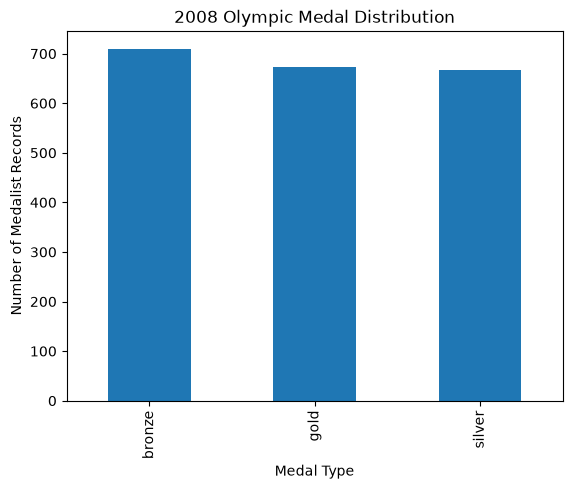

In [18]:
medal_counts = df_medalists["medal"].value_counts()

medal_counts.plot.bar()

plt.title("2008 Olympic Medal Distribution")
plt.xlabel("Medal Type")
plt.ylabel("Number of Medalist Records")
plt.show()

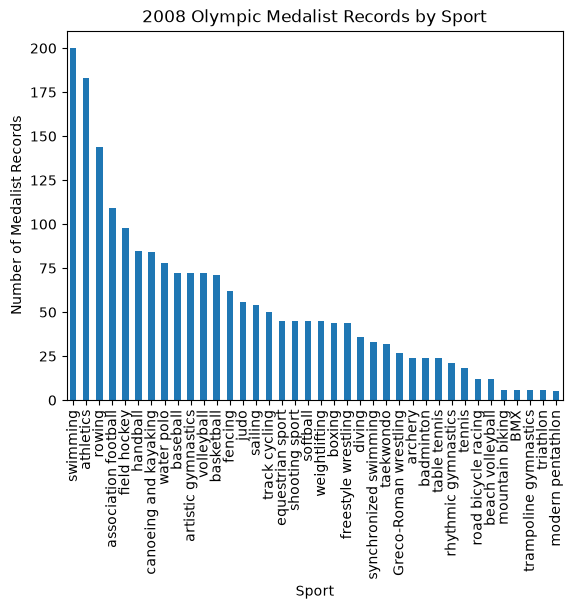

In [19]:
sport_counts = df_medalists["sport"].value_counts()

sport_counts.plot.bar()

plt.title("2008 Olympic Medalist Records by Sport")
plt.xlabel("Sport")
plt.ylabel("Number of Medalist Records")
plt.show()

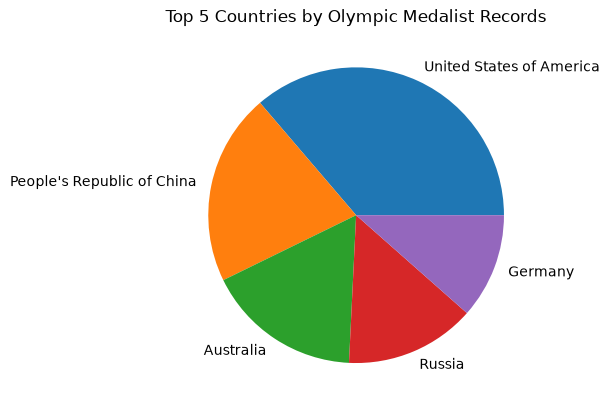

In [20]:
country_counts = df_medalists["country_medal"].value_counts().head(5)

country_counts.plot.pie()

plt.title("Top 5 Countries by Olympic Medalist Records")
plt.ylabel("")
plt.show()

For my visualizations I decided to do two bar charts and one pie chart.I created a bar chart showing the distribution of gold, silver, and bronze medalist records. I used value_counts() to count each medal type and plot.bar() to display the results. 

For my second visualization, I created a bar chart showing the number of medalist records across different Olympic sports. I used value_counts() to count the records and plot.bar() to display them. This helped me compare which sports had the most medalist records.

For my third visualization, I created a pie chart showing the five countries with the most medalist records. I used value_counts() to count the records for each country and head(5) to select the top five countries. I then used plot.pie() to create the visualization.

